# 09. A grande final: os filtros entregues

| Filtro | Para quê | Configuração |
|---|---|---|
| **Especialista** | esta caixa (farmer-d) | Stacking 7 do algoritmo genético (D8) |
| **Generalista** | caixas novas | Stacking 8 padrão: Stacking 7 padrão + TabPFN-3.5-Plus (D10, regra pré-registrada) |
| **Generalista sem chave** | caixas novas, sem internet (usado na demo) | Stacking 7 padrão |
| **Linha de base** | referência simples | LinearSVC com TF-IDF log |

Todos usam o **limiar de custo**: perder 1 e-mail real custa o mesmo que receber 9 spams. Este script treina os
filtros nos 5172 e-mails, reúne os números das quatro avaliações e grava `resultados/metricas_finais.json`, a
fonte única de README, notebook, apresentações e demo.

In [1]:
import datetime as dt
import json
import os
import platform
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict

import spamfilter
from spamfilter import caminhos, dados, externo, graficos, metricas, modelos, saidas
from spamfilter.dados import SEED
from spamfilter.filtro import FiltroStacking
from spamfilter.motor import Motor

base = dados.carregar()
m = Motor(base, log=lambda *a: None)
CONF = m.adicionar_divisoes([201, 202, 203, 204])
m.adicionar_teste_trancado()
Xext, yext, _ = externo.carregar_externo(base)
m.adicionar_externo(Xext)
ESP, PAD = modelos.STACKING7_ESPECIALISTA, modelos.STACKING7_PADRAO
TABN = caminhos.EXPERIMENTOS / "05_tabpfn" / "cache_tabpfn" / "nuvem"

## 1. Treinar e salvar os filtros (nos 5172 e-mails)

In [2]:
PASTA = caminhos.RESULTADOS / "modelos"
def ztr_externo(cfg):
    return np.column_stack([np.load(m.arquivo("externo", f, cfg[i]))["ztr"] for i, f in enumerate(modelos.FAMILIAS)])

FILTROS = {}
for nome, cfg in [("especialista", ESP), ("stacking7_padrao", PAD)]:
    arq = PASTA / f"{nome}.joblib"
    if not arq.exists():                       # cerca de 2 min por filtro; depois fica salvo
        FiltroStacking.treinar(nome, cfg, base, ztr_externo(cfg)).salvar(arq)
    FILTROS[nome] = FiltroStacking.carregar(arq)
    print(f"{nome}: limiar de custo {FILTROS[nome].limiar:.3f} | arquivo {arq.stat().st_size / 2**20:.1f} MB")

# Generalista = Stacking 8: os membros do Stacking 7 padrão + a nota do TabPFN; o meta-modelo tem 8 entradas.
ztr8 = np.column_stack([ztr_externo(PAD), np.load(TABN / "externo.npz")["ztr"]])
meta8 = modelos.meta(modelos.META_C[PAD[-1]])
oof8 = cross_val_predict(meta8, ztr8, base.y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
meta8.fit(ztr8, base.y)
generalista = dict(nome="generalista_stacking8", membros="stacking7_padrao.joblib", oitavo_membro="TabPFN-3.5-Plus (nuvem, tabpfn-client)",
                   meta_modelo=meta8, limiar=float(metricas.limiar_custo(oof8, base.y)))
import joblib
joblib.dump(generalista, PASTA / "generalista_stacking8.joblib", compress=3)
lsvc = modelos.construir("LinearSVC", modelos.LINEARSVC_PADRAO).fit(base.X, base.y)
ztr_l = np.load(m.arquivo("externo", "LinearSVC", modelos.LINEARSVC_PADRAO))["ztr"]
joblib.dump(dict(nome="linha_de_base_linearsvc", modelo=lsvc, limiar=float(metricas.limiar_custo(ztr_l, base.y))), PASTA / "linha_de_base.joblib", compress=3)
print(f"generalista (Stacking 8): limiar {generalista['limiar']:.3f} | pesos do meta-modelo: "
      + ", ".join(f"{n} {w:+.2f}" for n, w in zip(modelos.FAMILIAS + ["TabPFN"], meta8[-1].coef_.ravel())))

especialista: limiar de custo 0.711 | arquivo 42.4 MB


stacking7_padrao: limiar de custo 0.807 | arquivo 26.8 MB
generalista (Stacking 8): limiar 0.881 | pesos do meta-modelo: Reg. Logística +0.91, SVM RBF +1.23, kNN cosseno +1.52, MLP -0.32, Naive Bayes -0.00, Extra Trees +0.28, LightGBM +1.02, TabPFN +1.55


## 2. As quatro avaliações de cada filtro

                       MCC (20 folds)  custo/mil (20 folds)  teste trancado: reais na lixeira  teste trancado: spams que passaram  custo/mil Enron2-6  custo/mil SpamAssassin
especialista                     0.97                 36.62                               1.0                                10.0              207.65                 2416.47
generalista                      0.97                 38.19                               2.0                                13.0              138.50                 1119.91
generalista_sem_chave            0.97                 41.51                               0.0                                17.0              177.45                 1977.17
linha_de_base                    0.96                 52.03                               3.0                                23.0              156.94                  528.45


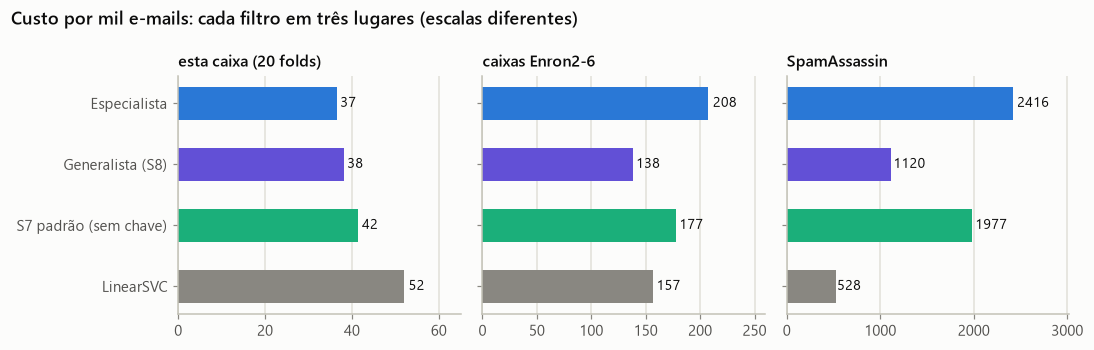

In [3]:
def tab_nuvem(chave, te):
    z = np.load(TABN / f"{chave}.npz"); return z["ztr"], z[f"zte_{te}"]

def prever(nome, chave, te="te"):
    if nome == "especialista":
        return m.prever_stacking(ESP, chave, te)
    if nome == "generalista":
        return m.prever_stacking(PAD, chave, te, extra=tab_nuvem(chave, te))
    if nome == "generalista_sem_chave":
        return m.prever_stacking(PAD, chave, te)
    return m.prever_linearsvc(modelos.LINEARSVC_PADRAO, chave, te)

NOMES = ["especialista", "generalista", "generalista_sem_chave", "linha_de_base"]
cv20 = {n: pd.DataFrame([metricas.metricas(m.y_teste(c), *prever(n, c)) for c in CONF]).mean().to_dict() for n in NOMES}
ext = {}
for n in NOMES:
    por = {b: metricas.metricas(yext[b], *prever(n, "externo", b)) for b in Xext}
    ext[n] = dict(pd.DataFrame(por).T.mean().to_dict(), por_base=por)
sa = {r["metodo"]: r for r in saidas.ler("08_terceira_base")["terceira_base"]["metodos"]}
MAPA_SA = {"especialista": "Stacking 7 especialista", "generalista": "Stacking 8 padrão (+TabPFN)",
           "generalista_sem_chave": "Stacking 7 padrão (Generalista atual)", "linha_de_base": "LinearSVC padrão"}

# Base de teste trancada. Os 7 membros e o LinearSVC já estão no cache (usos 1 e 2, experimentos 02 e 03).
# O Stacking 8 precisa do TabPFN treinado nos 80% (5 treinos internos + 1 final): 3º uso, só para relatar (D10 já decidida).
arq_tt = caminhos.RESULTADOS / "cache_tabpfn" / "teste_trancado.npz"
py_nuvem = caminhos.RAIZ / ".venv-tabpfn-nuvem" / "Scripts" / "python.exe"
if not arq_tt.exists() and os.environ.get("TABPFN_TOKEN") and py_nuvem.exists():
    dev = m.dev; _, ydv, gdv = m.bases["dev"]
    pares = {f"in{k}": (dev[a], dev[b]) for k, (a, b) in enumerate(dados.divisoes(ydv, gdv, SEED))}
    pares["final"] = (dev, m.teste)
    ent = arq_tt.with_name("teste_trancado_entrada.npz")
    np.savez(ent, chaves=np.array(list(pares)), **{f"tr_{k}": v[0] for k, v in pares.items()}, **{f"te_{k}": v[1] for k, v in pares.items()})
    subprocess.run([str(py_nuvem), str(caminhos.RAIZ / "scripts" / "tabpfn_nuvem_lotes.py"), str(caminhos.CSV), str(ent), str(arq_tt)], check=True)
yt = base.y[m.teste]
def teste_trancado(n):
    if n == "generalista":
        if not arq_tt.exists():
            return None
        Z = np.load(arq_tt); _, ydv, gdv = m.bases["dev"]; ztr = np.zeros(len(m.dev))
        for k, (a, b) in enumerate(dados.divisoes(ydv, gdv, SEED)):
            ztr[b] = Z[f"zte_in{k}"]
        r = m.prever_stacking(PAD, "teste", "teste", extra=(ztr, Z["zte_final"]))
    else:
        r = prever(n, "teste", "teste")
    fp, fn = metricas.contagem_erros(yt, r[2])
    return dict(metricas.metricas(yt, *r), email_real_lixeira=fp, spam_passou_n=fn, custo=9 * fp + fn)
tt = {n: teste_trancado(n) for n in NOMES}

FIN = pd.DataFrame({n: {"MCC (20 folds)": cv20[n]["mcc"], "custo/mil (20 folds)": cv20[n]["custo_por_mil"],
                        "teste trancado: reais na lixeira": (tt[n] or {}).get("email_real_lixeira"),
                        "teste trancado: spams que passaram": (tt[n] or {}).get("spam_passou_n"),
                        "custo/mil Enron2-6": ext[n]["custo_por_mil"], "custo/mil SpamAssassin": sa[MAPA_SA[n]]["custo_por_mil"]} for n in NOMES}).T
print(FIN.round(2).to_string())

fig, axs = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
rot = {"especialista": "Especialista", "generalista": "Generalista (S8)", "generalista_sem_chave": "S7 padrão (sem chave)", "linha_de_base": "LinearSVC"}
cor = {"especialista": graficos.CATEGORICA[0], "generalista": graficos.CATEGORICA[6], "generalista_sem_chave": graficos.CATEGORICA[2], "linha_de_base": graficos.TINTA_MUDA}
for ax, (col, tit) in zip(axs, [("custo/mil (20 folds)", "esta caixa (20 folds)"), ("custo/mil Enron2-6", "caixas Enron2-6"), ("custo/mil SpamAssassin", "SpamAssassin")]):
    v = FIN[col]
    ax.barh(range(len(NOMES)), v.values, height=0.55, color=[cor[n] for n in NOMES])
    for i, x in enumerate(v.values):
        ax.text(x * 1.02, i, f"{x:.0f}", va="center", fontsize=9)
    ax.set_title(tit, fontsize=10.5); ax.grid(axis="y", visible=False); ax.set_xlim(0, v.max() * 1.25)
axs[0].set_yticks(range(len(NOMES)), [rot[n] for n in NOMES]); axs[0].invert_yaxis()
fig.suptitle("Custo por mil e-mails: cada filtro em três lugares (escalas diferentes)", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
graficos.mostrar(fig, "09_filtros_finais")

## 3. Simulador do limiar (para os slides)
Probabilidades de teste dos 20 folds juntas: para cada limiar, quantos e-mails reais vão para a lixeira e
quanto spam passa.

In [4]:
grade = np.round(np.linspace(0.01, 0.99, 99), 2)
simul = {}
for n in ["especialista", "generalista", "generalista_sem_chave"]:
    ps, yy, lims = [], [], []
    for c in CONF:
        p, _, yc = prever(n, c); ps.append(p); yy.append(m.y_teste(c))
    p, yy = np.concatenate(ps), np.concatenate(yy)
    simul[n] = [dict(limiar=float(t), real_lixeira=float(((p > t) & (yy == 0)).sum() / (yy == 0).sum()),
                     spam_passou=float(((p <= t) & (yy == 1)).sum() / (yy == 1).sum()),
                     custo_por_mil=float(metricas.custo_por_mil(yy, (p > t).astype(int)))) for t in grade]

## 4. Exemplos para a demonstração (e-mails que o treino nunca viu)

In [5]:
txt3, y3, n3 = externo.ler_tar(3); txt5, y5, n5 = externo.ler_tar(5)
r3 = np.random.default_rng(7)
exemplo_real = txt3[int(r3.choice(np.flatnonzero(y3 == 0)))]
exemplo_spam = txt5[int(r3.choice(np.flatnonzero(y5 == 1)))]
exemplo_pt = ("Subject: Prorrogação da entrega do Projeto 3\n"
              "Prezados alunos,\n\nInformamos que a entrega do Projeto 3 de Data Science 2 foi prorrogada para a próxima "
              "segunda-feira. O notebook deve rodar do início ao fim sem erros. Dúvidas podem ser enviadas pelo fórum da disciplina.\n\n"
              "Atenciosamente,\nCoordenação")
EXEMPLOS = []
for rotulo, texto, origem in [("spam", exemplo_spam, "Enron5 (caixa nunca vista)"), ("e-mail real", exemplo_real, "Enron3 (caixa nunca vista)"),
                              ("e-mail real (português)", exemplo_pt, "texto fictício escrito para a demo")]:
    etapas = {n: FILTROS[n].explicar(texto) for n in ["especialista", "stacking7_padrao"]}
    e = etapas["especialista"]
    nz = np.flatnonzero(e["vetor"])
    EXEMPLOS.append(dict(rotulo=rotulo, origem=origem, texto=texto[:1500], texto_aueb=e["texto_aueb"][:1500], cobertura=e["cobertura"],
                         colunas_nao_zero=e["colunas_nao_zero"], palavras_encontradas=e["palavras_encontradas"],
                         vetor_nao_zero={str(base.vocab[j]): int(e["vetor"][j]) for j in nz},
                         etapas={n: {k: v for k, v in d.items() if k not in ("vetor", "presenca", "texto_aueb", "palavras_encontradas")} for n, d in etapas.items()}))
    print(f"{rotulo:24s} | cobertura {e['cobertura']:.0%} | P(spam) especialista {etapas['especialista']['prob_spam']:.3f} "
          f"(limiar {etapas['especialista']['limiar']:.3f}) | S7 padrão {etapas['stacking7_padrao']['prob_spam']:.3f}")

spam                     | cobertura 83% | P(spam) especialista 0.987 (limiar 0.711) | S7 padrão 0.937
e-mail real              | cobertura 81% | P(spam) especialista 0.001 (limiar 0.711) | S7 padrão 0.000


e-mail real (português)  | cobertura 16% | P(spam) especialista 0.997 (limiar 0.711) | S7 padrão 0.994


## 5. `metricas_finais.json`

In [6]:
S = {k: saidas.ler(k) for k in ["01_dados", "02_nao_supervisionado", "03_torneio", "04_stacking", "05_genetico",
                                "06_corrida_tabpfn", "07_contra_estudo", "08_terceira_base"]}
LIMIAR = {"especialista": FILTROS["especialista"].limiar, "generalista": generalista["limiar"],
          "generalista_sem_chave": FILTROS["stacking7_padrao"].limiar, "linha_de_base": None}
def finais(n, cfg_desc):
    return dict(config=cfg_desc, limiar_custo=LIMIAR[n], cv20=cv20[n], teste_trancado=tt[n], externo=ext[n], spamassassin=sa[MAPA_SA[n]])
METRICAS = {
    "versao_contrato": 1,
    "meta": dict(gerado_em=dt.datetime.now().isoformat(timespec="seconds"), versao_pacote=spamfilter.__version__,
                 python=platform.python_version(), seed_teste=dados.SEED_TESTE, custo_fp=metricas.CUSTO_FP, custo_fn=metricas.CUSTO_FN),
    "base": S["01_dados"]["base"], "metricas_didaticas": S["01_dados"]["metricas_didaticas"],
    "palavras": S["01_dados"]["palavras"], "dominio": S["01_dados"]["dominio"],
    "protocolo": dict(teste_trancado=dict(n=int(len(m.teste)), email_real=int((yt == 0).sum()), spam=int((yt == 1).sum()), usos=3),
                      folds_confirmacao=20, piso_mcc_detectavel={str(r["folds"]): r["menor_dif_detectavel"] for r in S["05_genetico"]["genetico"]["piso"]}),
    "nao_supervisionado": S["02_nao_supervisionado"]["nao_supervisionado"],
    "torneio": S["03_torneio"]["torneio"], "achados": S["03_torneio"]["achados"], "rodada2": S["03_torneio"]["rodada2"],
    "stacking": S["04_stacking"]["stacking"], "genetico": S["05_genetico"]["genetico"],
    "corrida": S["06_corrida_tabpfn"]["corrida"], "tabpfn": S["06_corrida_tabpfn"]["tabpfn"],
    "terceira_base": S["08_terceira_base"]["terceira_base"],
    "finais": {"especialista": finais("especialista", modelos.descrever_stacking(ESP)),
               "generalista": finais("generalista", dict(modelos.descrever_stacking(PAD), oitavo_membro="TabPFN-3.5-Plus")),
               "generalista_sem_chave": finais("generalista_sem_chave", modelos.descrever_stacking(PAD)),
               "linha_de_base": finais("linha_de_base", {"LinearSVC": modelos.descrever("LinearSVC", modelos.LINEARSVC_PADRAO)})},
    "simulador_limiar": simul,
    "contra_estudo": S["07_contra_estudo"]["contra_estudo"],
    "exemplos_demo": EXEMPLOS,
    "fontes": {k: v.get("fonte") for k, v in S.items()} | {"finais": "scripts/09_modelos_finais.py"},
}
saidas.gravar("metricas_finais", METRICAS, fonte="scripts/09_modelos_finais.py")
print(f"gravado: resultados/metricas_finais.json ({(caminhos.RESULTADOS / 'metricas_finais.json').stat().st_size / 1024:.0f} KB)")

gravado: resultados/metricas_finais.json (407 KB)
